# Problem set 8

### Problem 1: Trapezium vs Simpson rule

#### Part 1 - Trapezium rule

Implement the function `trapz` that calculates integrals using the Trapezium rule. The documentation for the function is described below.

In [ ]:
def trapz(f, a, b, n):
    """
    Approximate the integral of f(x) from a to b by the composite trapezium rule

    The trapezium rule approximates the integral int_a^b f(x) dx by the sum:
    (dx / 2) sum_{i=1}^{n} (f(x_i) + f(x__{i-1}))
    where x_i = a + i*dx and dx = (b-a)/n.

    Parameters
    ----------
    f (function):  Single variable integrand
    a, b (floats): Interval of integration [a,b]
    n (int):       Number of subintervals of [a,b]

    Returns
    -------
    (float):       Approximation of the integral of f(x) from a to b using
                   the trapezium rule with n subintervals of equal length

    Example
    -------
    >>> trapz(lambda x: math.sin(x), 0, math.pi / 2, 1000)
    0.999999794383233
    
    """
    dx = (b - a) / n
    integral = (f(a) + f(b)) / 2
    for i in range(1, n):
        xi = a + i * dx
        integral += f(xi)
    integral *= dx
    return integral

# Example usage
import math 

def f(x):
    return(math.sin(x))

result = trapz(f, 0, math.pi / 2, 1000)
print(result)  # Expected output: approximately 1, since the integral of sin(x) from 0 to pi/2 is 1
    

#### Part 2 - Simpson rule

Implement the function `simps` that calculates integrals using the Trapezium rule. The documentation for the function is described below.

In [ ]:
def simps(f, a, b, n):
    """
    Approximate the integral of f(x) from a to b by Simpson's 1/3 rule.

    Simpson's 1/3 rule approximates the integral int_a^b f(x) dx by the sum:
    (dx/3) sum_{i=1}^{n} (f(x_{2i-2} + 4f(x_{2i-1}) + f(x_{2i}))
    where x_i = a + i*dx and dx = (b - a)/2n.

    Parameters
    ----------
    f (function):    Single variable integrand
    a , b (numbers): Interval of integration [a,b]
    n (int):         Number of subintervals of [a,b]

    Returns
    -------
    (float):         Approximation of the integral of f(x) from a to b using
                     Simpson's rule with n subintervals of equal length.

    Examples
    --------
    >>> simps(lambda x : 3*x**2,0,1,10)
    1.0
    """
    dx = (b - a) / (2*n)
    integral = f(a) + f(b)
    for i in range(1, 2*n, 2):
        xi = a + i * dx
        integral += 4 * f(xi)
    for i in range(2, 2*n, 2):
        xi = a + i * dx
        integral += 2 * f(xi)
    integral *= dx / 3
    
    return integral

# Example usage
import math

def f(x):
    return math.sin(x)
    
result = simps(f, 0, math.pi / 2, 10)
print(result)  # Expected output close to 1.0

1.0000002115465914


#### Part 3 - Error estimate

Consider the function $f(x) = \sin(x)$ on the interval $[0, {\pi/2}]$. We want to evaluate the integral
$$\int_0^{\pi/2} f(x) dx$$
by means of the trapezium and Simpson's 1/3 rule, and compare the order of the approximation error for both methods. Complete the table below for both methods and reflect on how the error decreases with the number of subintervals.

| $n$ | Approx. Integral | Exact Integral | Absolute error | Factor = Error(n-1) / Error(n) |
| ---: | :--------------: | :------------: | :------------: | :----------------------------: |
| 1    |                  |                |                | Can't compute                          |
| 2    |                  |                |                |                                |
| 4    |                  |                |                |                                |
| 8    |                  |                |                |                                |
| 16   |                  |                |                |                                |
| 32   |                  |                |                |                                |

In [ ]:
import math
def f(x):
    return math.sin(x)
I_exact = 1
results_trapz = []
results_simps = []

subintervals = [2, 4, 8, 16, 32, 64]

print("2n   Approx. Integral     Exact Integral   Absolute error       Factor")
print("----------------------------------------------------------------------")

method = trapz
for n in subintervals:
    I_approx = method(f, 0, math.pi/2, n)
    error = abs(I_approx - I_exact)
    
    if n >= 4:
        I_approx_previous = method(f, 0, math.pi/2, n//2)
        error_previous = abs(I_approx_previous - I_exact)

    if n >= 4:
        print(f"{n:2d} {I_approx:18.8f} {I_exact:18.8f} {error:16.8f} {(error_previous/error):12.6f}")
    else:
        print(f"{n:2d} {I_approx:18.8f} {I_approx:18.8f} {error:16.8f}")


### Problem 2: Monte Carlo integration

#### Part 1 - Monte Carlo
Write a function `montecarlo` that, by way of the Monte Carlo method, calculates the integral of any mathematical function with specified bounds of integration. The function should accept the following five arguments:

- `f`: a real-valued function of which the integral will be calculated;
- `x1`: the minimum x-value surrounding the integral area;
- `y1`: the minimum y-value surrounding the integral area;
- `x2`: the maximal x-value surrounding the integral area;
- `y2`: the maximal y-value surrounding the integral area.

The function `montecarlo` should **return** the area under the graph. 

#### Part 2 - Plot simulation
Write a function `plot_montecarlo` that plots the graph of the integrand and the points *within* the integral area (the 'correct' points) in green and the points *outside of* the integral area (the 'incorrect' points) in red. The function should accept the same input parameters as `montecarlo`: `f`, `x1`, `y1`, `x2`, `y2`. 

Hints: 
- First create the graph of the function so you have a clear view of what area you are integrating.
- Think carefully about how to deal with parts of the integral area that are situated below the x-axis: when encountering negative integral areas, make sure to deduct them from the positive area!

In [ ]:
import random
import matplotlib.pyplot as plt

def montecarlo(f, x1, y1, x2, y2, num_points=10000):
    """
    Approximates the integral of f using the Monte Carlo method.
    
    Parameters
    ----------
    f (function): Real-valued function to integrate
    x1, x2 (floats): x-bounds of the region
    y1, y2 (floats): y-bounds of the region
    num_points (int): Number of random points to sample (default is 10000)
    
    Returns
    -------
    float: Approximated integral of f
    """
    correct_points = 0

    for _ in range(num_points):
        x_rand = random.uniform(x1, x2)
        y_rand = random.uniform(y1, y2)
        if 0 <= y_rand <= f(x_rand):
            correct_points += 1
        elif 0 >= y_rand >= f(x_rand):
            correct_points -= 1
    area_box = (x2 - x1) * (y2 - y1)
    integral = area_box * (correct_points / num_points)
    return integral

def plot_montecarlo(f, x1, y1, x2, y2, num_points=10000):
    """
    Visualizes the Monte Carlo integration
    
    Parameters
    ----------
    f (function): Real-valued function to integrate
    x1, x2 (floats): x-bounds of the region
    y1, y2 (floats): y-bounds of the region
    num_points (int): Number of random points to sample (default is 1000)
    """
    x_vals = []
    y_vals = []
    dx = (x2 - x1) / 1000
    x = x1
    while x <= x2:
        x_vals.append(x)
        y_vals.append(f(x))
        x += dx
    below_x, below_y = [], []
    above_x, above_y = [], []

    for _ in range(num_points):
        x_r = random.uniform(x1, x2)
        y_r = random.uniform(y1, y2)
        if 0 <= y_r <= f(x_r) or 0 >= y_r >= f(x_r):
            below_x.append(x_r)
            below_y.append(y_r)
        else:
            above_x.append(x_r)
            above_y.append(y_r)

    plt.plot(x_vals, y_vals, label='f(x)', color='blue')
    plt.plot(below_x, below_y, color='green', marker='.', linestyle = '', markersize = 2, label='Correct points')
    plt.plot(above_x, above_y, color='red', marker='.', linestyle = '', markersize = 2, label='Incorrect points')

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Monte Carlo Integration')
    plt.show()

0.7659202889451915


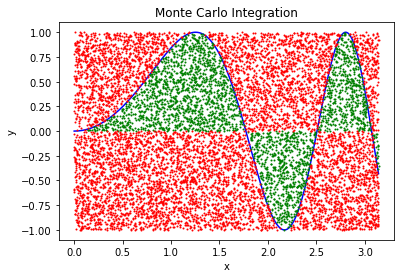

In [28]:
# To test your code, you can use the following function.
# You can also create your own test cases,
# for example like the integral from 0 to 1 of f(x) = x^2.

import math

def f(x):
    return(math.sin(x**2))

print(montecarlo(f, 0, -1, math.pi, 1))
plot_montecarlo(f, 0, -1, math.pi, 1, 10000)

Expected output (close to, there is a certain degree of variance in output):

    0.773

<img src="https://i.ibb.co/k3gNLwR/sinsquare.png" width=400 border="0">

### Problem 3: Twitter egg

Write a program that calculates the area of the Twitter egg, the circumference of which is defined by
$$\sqrt{x^2 + y^2} + \tfrac{2}{3} \sqrt{x^2 + \left(\tfrac{5}{6} - y\right)^2} = 1.$$
<center><img src="https://i.ibb.co/swKq4HF/Twitter-Egg.png" width=600 border="0"></center>
Generate a total of ten thousand points and calculate the correct area. 

Your program should consist of two parts:

- Print the answer of the area to the screen, 2 decimals precise.

      The area of the Twitter egg is x.xx

- Plot the distribution of correct and incorrect points (as per the example above).

Hint: What would be a sensible bounding area to use for the egg? 

The area of the Twitter egg is 0.82


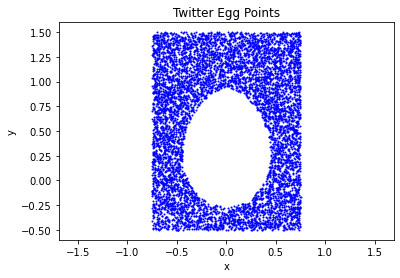

In [ ]:
import matplotlib.pyplot as plt
import random
import math

def twitter_egg_area(num_points=10_000):
    """
    Estimate the area of the Twitter egg using Monte Carlo integration.
    
    Parameters
    ----------
    num_points (int): Total number of points to generate

    Returns
    -------
    None
    """
    x_min, x_max = -0.75, 0.75
    y_min, y_max = -0.5, 1.5
    def is_inside(x, y):
        return math.sqrt(x**2 + y**2) + (2/3) * math.sqrt(x**2 + (5/6 - y)**2) <= 1

    correct_x = []
    correct_y = []
    incorrect_x = []
    incorrect_y = []
    points_inside = 0

    for _ in range(num_points):
        x = random.uniform(x_min, x_max)
        y = random.uniform(y_min, y_max)
        if is_inside(x, y):
            points_inside += 1
            correct_x.append(x)  
            correct_y.append(y) 
        else:
            incorrect_x.append(x)
            incorrect_y.append(y)
    final_area = (points_inside / num_points) * ((x_max - x_min) * (y_max - y_min))
    print(f"The area of the Twitter egg is {final_area:.2f}")

    plt.plot(incorrect_x, incorrect_y, color="blue", marker='.', linestyle='', markersize=2, label="Outside")
    plt.title("Twitter Egg Points")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.show()

# Run the program
twitter_egg_area()